# 01 — Inferência com SmolVLM (Semana 3)
Primeiro contato com um Small VLM: imagem + texto → texto. Objetivo é entender entrada e saída, sem avaliação formal.

Modelo: `HuggingFaceTB/SmolVLM-Instruct` (Marafioti et al. 2025).

In [1]:
from pathlib import Path
import torch
from PIL import Image, ImageDraw
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = 'HuggingFaceTB/SmolVLM-Instruct'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.bfloat16 if DEVICE == 'cuda' else torch.float32
print(DEVICE, DTYPE)

/home/edryck/Documentos/faculdade/ic/ic-visionexplain/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cpu torch.float32


In [2]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
model.eval()
print(f'{sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters')

Loading weights: 100%|██████████| 657/657 [00:10<00:00, 61.21it/s] 


2246M parameters


## Imagens de teste
Usa fotos em `../data/test_images/` (jpg/png) se existirem.

In [3]:
IMAGES_DIR = Path('../data/test_images')
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

test_images = {p.stem: Image.open(p).convert('RGB') for p in sorted(IMAGES_DIR.glob('*')) if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}}
if not test_images:
    print("Sem imagens de teste")

list(test_images)

['image-1', 'image-2', 'image-3', 'image-4', 'image-5']

## Função de inferência
Entrada: lista de mensagens (`role` + `content` com `{"type": "image"}` e `{"type": "text"}`). `apply_chat_template` converte para o prompt textual; o processor junta prompt e pixels. Saída: ids de tokens, decodificados para texto.

In [4]:
def ask(image, question, max_new_tokens=128, show_prompt=False):
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': question}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    if show_prompt:
        print(prompt)
    inputs = processor(text=prompt, images=[image], return_tensors='pt').to(DEVICE)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output_ids[:, inputs['input_ids'].shape[1]:]
    return processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()

## Formato de entrada e saída

input_ids        (1, 1197) torch.int64
attention_mask   (1, 1197) torch.int64
pixel_values     (1, 13, 3, 384, 384) torch.float32
pixel_attention_mask (1, 13, 384, 384) torch.int64

<|im_start|>User:<image>What is in this image?<end_of_utterance>
Assistant:
A group of people are sitting at a bar/pub/restaurant. There are 4 people in the foreground and 11 in the background. The people in the foreground are sitting at a table with a pizza on it. The pizza is round and has toppings on it. There are also some other food items on the table. The people in the background are standing behind the people in the foreground. There is a bar/counter behind the people in the foreground. There are bottles of alcohol on the bar/counter.


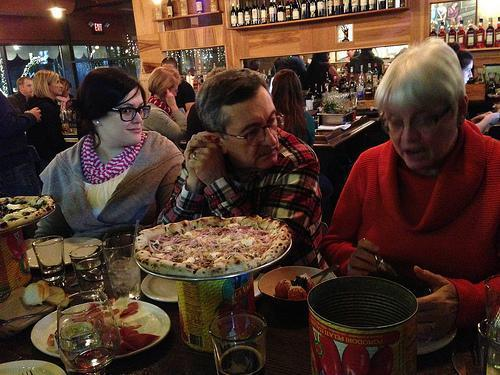

In [5]:
name = next(iter(test_images))
image = test_images[name]
inputs = processor(
    text=processor.apply_chat_template(
        [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': 'What is in this image?'}]}],
        add_generation_prompt=True,
    ),
    images=[image],
    return_tensors='pt',
)
for key, value in inputs.items():
    print(f'{key:16s}', tuple(value.shape), value.dtype)
print()
print(ask(image, 'What is in this image?', show_prompt=True))
image

## Perguntas simples por imagem

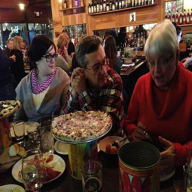

IMAGE: image-1
  Q: What is in this image?
  A: A group of people are sitting at a bar/pub/restaurant. There are 4 people in the foreground and 11 in the background. The people in the foreground are sitting at a table with a pizza on it. The pizza is round and has toppings on it. There are also some other food items on the table. The people in the background are standing behind the people in the foreground. There is a bar/counter behind the people in the foreground. There are bottles of alcohol on the bar/counter.

  Q: Describe the image in one sentence.
  A: The image depicts a group of people sitting at a bar or restaurant, likely enjoying a meal together. The setting appears to be a casual, possibly a pub or a cozy restaurant, as indicated by the presence of a bar counter and various bottles of liquor. The individuals are engaged in conversation, and some are actively eating, with one person holding a pizza on a pizza stand.

The individuals are dressed in casual attire, suggesting

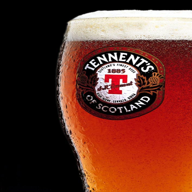

IMAGE: image-2
  Q: What is in this image?
  A: A glass of beer with the word Tennent's on it.

  Q: Describe the image in one sentence.
  A: The image is a close-up of a glass of beer with a label that says Tennent's of Scotland.

  Q: What colors do you see?
  A: The image has orange and black colors.



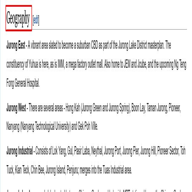

IMAGE: image-3
  Q: What is in this image?
  A: A screenshot of a news article about Juruong East.

  Q: Describe the image in one sentence.
  A: Page showing information about geography.

  Q: What colors do you see?
  A: Red



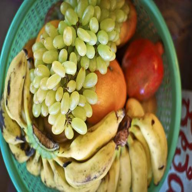

IMAGE: image-4
  Q: What is in this image?
  A: A green wicker fruit bowl filled with bananas, grapes, oranges, and a red apple.

  Q: Describe the image in one sentence.
  A: The image shows a green plastic fruit basket filled with various fruits. The basket contains several types of fruits, including green grapes, bananas, and red and yellow apples. The fruits are arranged in a visually appealing manner, with the green grapes placed on top of the bananas and the apples placed on the right side of the basket. The background of the image is blurred, focusing attention on the fruits in the basket. The image is taken from a top-down perspective, providing a clear view of the contents of the basket.

  Q: What colors do you see?
  A: Green, yellow, orange, red, and brown.



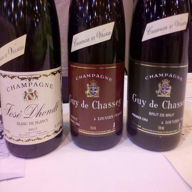

IMAGE: image-5
  Q: What is in this image?
  A: Three bottles of wine are lined up on a table.

  Q: Describe the image in one sentence.
  A: Three bottles of wine are lined up on a table.

  Q: What colors do you see?
  A: 3 bottles of wine



In [8]:
QUESTIONS = [
    'What is in this image?',
    'Describe the image in one sentence.',
    'What colors do you see?',
]

results = []
for name, image in test_images.items():
    display(image.resize((192, 192)))
    print('IMAGE:', name)
    for question in QUESTIONS:
        answer = ask(image, question)
        results.append({'image': name, 'question': question, 'answer': answer})
        print(f'  Q: {question}\n  A: {answer}\n')

## Teste de alucinação
Perguntas sobre objetos que não existem na imagem, ou contagem errada induzida. Anotar na célula seguinte onde o modelo inventa conteúdo.

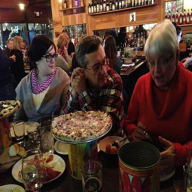

IMAGE: image-1
Q: What is the name of the dog in this image?
A: There is no dog present in this image.



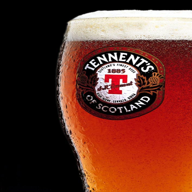

IMAGE: image-2
Q: How many people are standing next to the square?
A: There is no square present in the image, and therefore no people standing next to it.



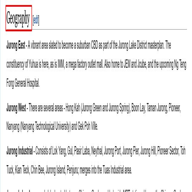

IMAGE: image-3
Q: Why is the yellow square the biggest one?
A: The yellow square is the biggest one because it is the title of the article.



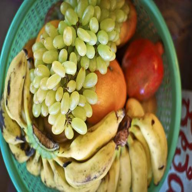

IMAGE: image-4
Q: What is the license plate of the car parked in front of the house?
A: 32345678.



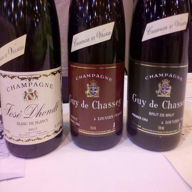

IMAGE: image-5
Q: Describe the person who is reading the text.
A: The person reading the text is likely a wine enthusiast or a wine professional, as they are familiar with the brands and types of wine being discussed. They may be attending a wine tasting event or a wine-related event, and are likely to be interested in learning more about the wines being discussed.



In [10]:
hallucination_probes = [
    ('image-1', 'What is the name of the dog in this image?'),
    ('image-2', 'How many people are standing next to the square?'),
    ('image-3', 'Why is the yellow square the biggest one?'),
    ('image-4', 'What is the license plate of the car parked in front of the house?'),
    ('image-5', 'Describe the person who is reading the text.'),
]

for name, question in hallucination_probes:
    if name not in test_images:
        print(f'Image not found: {name}')
        continue
    display(test_images[name].resize((192, 192)))
    print(f'IMAGE: {name}')
    print(f'Q: {question}')
    print(f'A: {ask(test_images[name], question)}\n')

## Observações
- Entrada: `input_ids` (texto + tokens `<image>` expandidos), `attention_mask`, `pixel_values` (imagem dividida em tiles) e `pixel_attention_mask`.
- Saída: ids de tokens; só os tokens novos (após o prompt) são decodificados.
- Alucinações observadas: 
  - Na imagem 1 e 2 o modelo não alucinou.
  - Na imagem 3, apenas errou a cor do quadrado.
  - Na imagem 4 e 5 o modelo alucinou demais.
- Tempo de inferência e memória: Levou muito tempo nas três perguntas por imagem (58min), no teste de alucinação também houve um tempo parecido (21min), parecido no sentido de tempo por pergunta, enquanto de memória não houve um grande consumo.